In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("Đã import thành công các thư viện cần thiết!")


Đã import thành công các thư viện cần thiết!


In [2]:
# 1. Đọc tệp CSV, phân tích cột 'Date' dưới dạng datetime, và thiết lập cột trên làm chỉ mục
csv_path = 'BT7.future-gc00-daily-prices.csv' if os.path.exists('BT7.future-gc00-daily-prices.csv') else os.path.join('btth', '7', 'BT7.future-gc00-daily-prices.csv')
data = pd.read_csv(csv_path)
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)

# 2. Sắp xếp DataFrame theo chỉ mục 'Date' theo thứ tự tăng dần
data.sort_index(inplace=True)

print("=== 5 DÒNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU ===")
display(data.head())

print("\n=== THÔNG TIN TỔNG QUAN BỘ DỮ LIỆU ===")
data.info()


=== 5 DÒNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU ===


,Open,High,Low,Close
Date,,,,
2009-04-24,905.50,915.40,904.20,914.10
2009-04-27,915.00,919.70,905.80,908.20
2009-04-28,907.20,907.70,884.60,893.60
2009-04-29,894.00,904.00,888.30,900.50
2009-04-30,898.60,900.80,880.10,891.20



=== THÔNG TIN TỔNG QUAN BỘ DỮ LIỆU ===
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3724 entries, 2009-04-24 to 2024-02-08
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Open    3724 non-null   object
 1   High    3724 non-null   object
 2   Low     3724 non-null   object
 3   Close   3724 non-null   object
dtypes: object(4)
memory usage: 145.5+ KB


In [3]:
# 3. Làm sạch cột "Close":
# - Loại bỏ dấu phẩy khỏi dữ liệu trong cột "Close"
if data['Close'].dtype == object:
    data['Close'] = data['Close'].str.replace(',', '')

# - Chuyển đổi giá trị thành kiểu số học
data['Close'] = pd.to_numeric(data['Close'], errors='coerce')

# - Thay thế các giá trị vô hạn (nếu có) thành NaN
data['Close'] = data['Close'].replace([np.inf, -np.inf], np.nan)

# - Loại bỏ các dòng có giá trị NaN trong cột "Close"
initial_len = len(data)
data.dropna(subset=['Close'], inplace=True)

print(f"Số dòng dữ liệu sau khi làm sạch: {len(data)} (Loại bỏ {initial_len - len(data)} dòng)")
print("\n=== THỐNG KÊ MÔ TẢ CỘT 'Close' ===")
display(data[['Close']].describe())


Số dòng dữ liệu sau khi làm sạch: 3724 (Loại bỏ 0 dòng)

=== THỐNG KÊ MÔ TẢ CỘT 'Close' ===


,Close
count,3724.000000
mean,1468.537997
std,289.872175
min,888.200000
25%,1239.775000
50%,1353.750000
75%,1735.775000
max,2093.100000


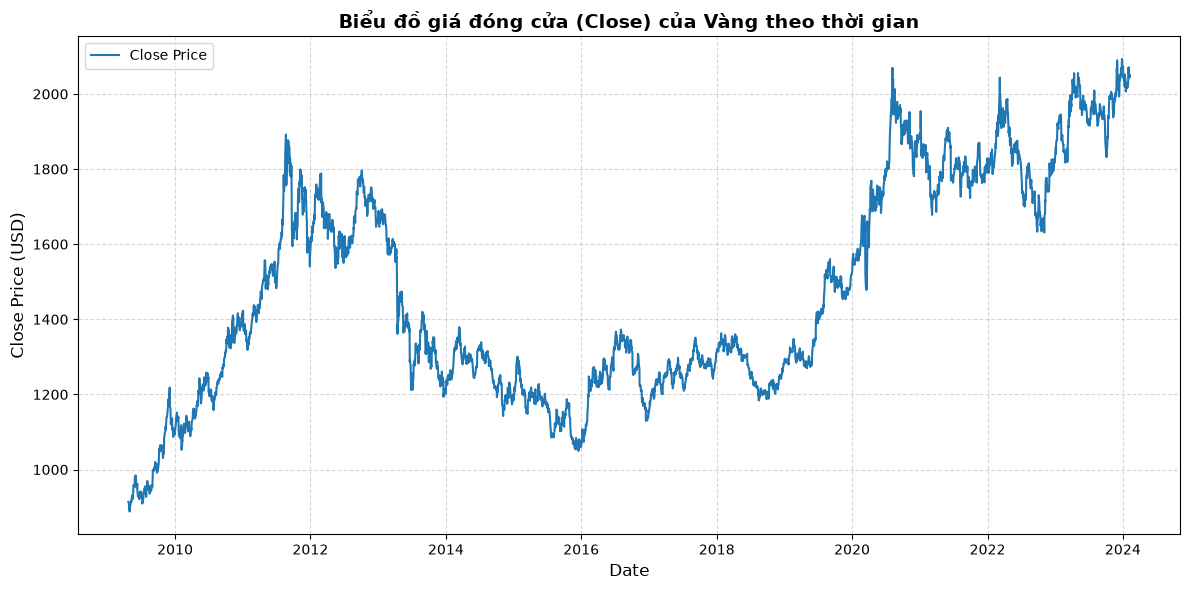

In [4]:
# 4. Vẽ đồ thị giá "Close" theo thời gian
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Close'], color='#1f77b4', linewidth=1.5, label='Close Price')
plt.title('Biểu đồ giá đóng cửa (Close) của Vàng theo thời gian', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Close Price (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


In [5]:
# 5. Kiểm tra tính dừng (stationarity) và thực hiện phép sai phân (differencing)
# Kiểm định Augmented Dickey-Fuller (ADF) trên chuỗi gốc
result_raw = adfuller(data['Close'])
adf_stat_raw = result_raw[0]
p_val_raw = result_raw[1]

print("=== KẾT QUẢ KIỂM ĐỊNH ADF TRÊN CHUỖI GỐC ===")
print(f"ADF Statistic (Gốc): {adf_stat_raw:.4f}")
print(f"p-value (Gốc): {p_val_raw:.4f}")
if p_val_raw > 0.05:
    print("Giải thích: Chuỗi gốc là không dừng (Non-Stationary) vì p-value > 0.05.")
else:
    print("Giải thích: Chuỗi gốc là chuỗi dừng (Stationary) vì p-value <= 0.05.")

# Thực hiện sai phân 1 bậc
data['Close_Diff'] = data['Close'].diff()

# Kiểm định ADF trên chuỗi đã sai phân (Differenced)
result_diff = adfuller(data['Close_Diff'].dropna())
adf_stat_diff = result_diff[0]
p_val_diff = result_diff[1]

print("\n=== KẾT QUẢ KIỂM ĐỊNH ADF TRÊN CHUỖI ĐÃ SAI PHÂN ===")
print(f"ADF Statistic (sai phân): {adf_stat_diff:.4f}")
print(f"p-value (sai phân): {p_val_diff:.4f}")
if p_val_diff < 0.05:
    print("Giải thích: Chuỗi đã chênh lệch là dừng (Stationary) vì p-value < 0.05.")
else:
    print("Giải thích: Chuỗi chưa dừng, cần xem xét sai phân bậc cao hơn.")


=== KẾT QUẢ KIỂM ĐỊNH ADF TRÊN CHUỖI GỐC ===
ADF Statistic (Gốc): -1.4367
p-value (Gốc): 0.5646
Giải thích: Chuỗi gốc là không dừng (Non-Stationary) vì p-value > 0.05.

=== KẾT QUẢ KIỂM ĐỊNH ADF TRÊN CHUỖI ĐÃ SAI PHÂN ===
ADF Statistic (sai phân): -19.1308
p-value (sai phân): 0.0000
Giải thích: Chuỗi đã chênh lệch là dừng (Stationary) vì p-value < 0.05.


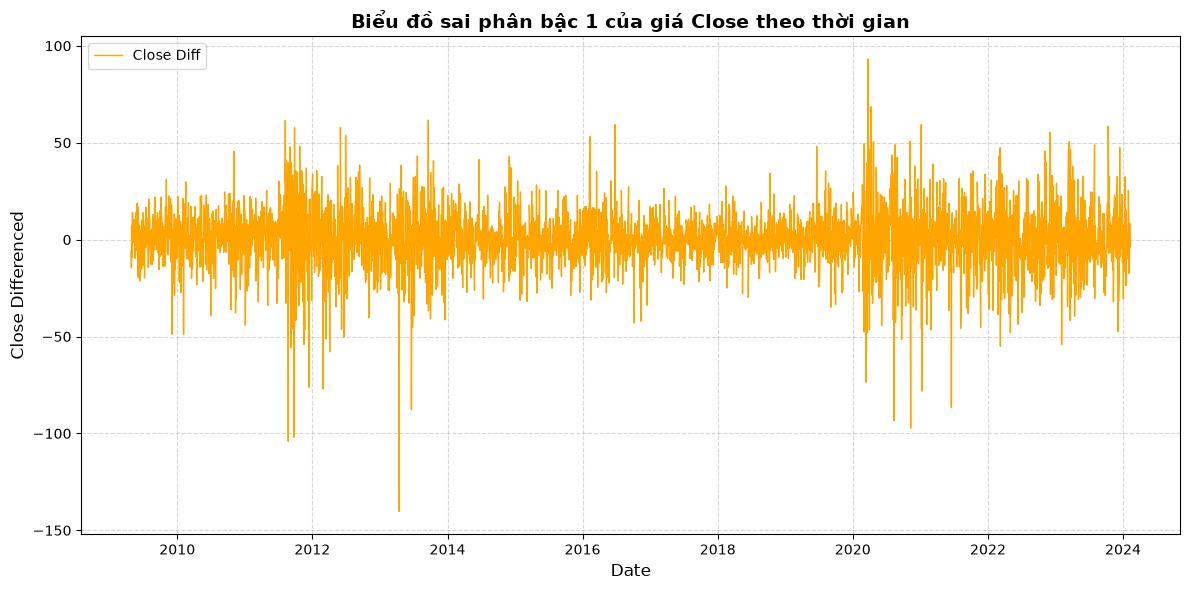

In [10]:
# 6. Vẽ đồ thị giá "Close" đã sai phân (differenced) với màu cam (orange)
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Close_Diff'], color='orange', linewidth=1, label='Close Diff')
plt.title('Biểu đồ sai phân bậc 1 của giá Close theo thời gian', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Close Differenced', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


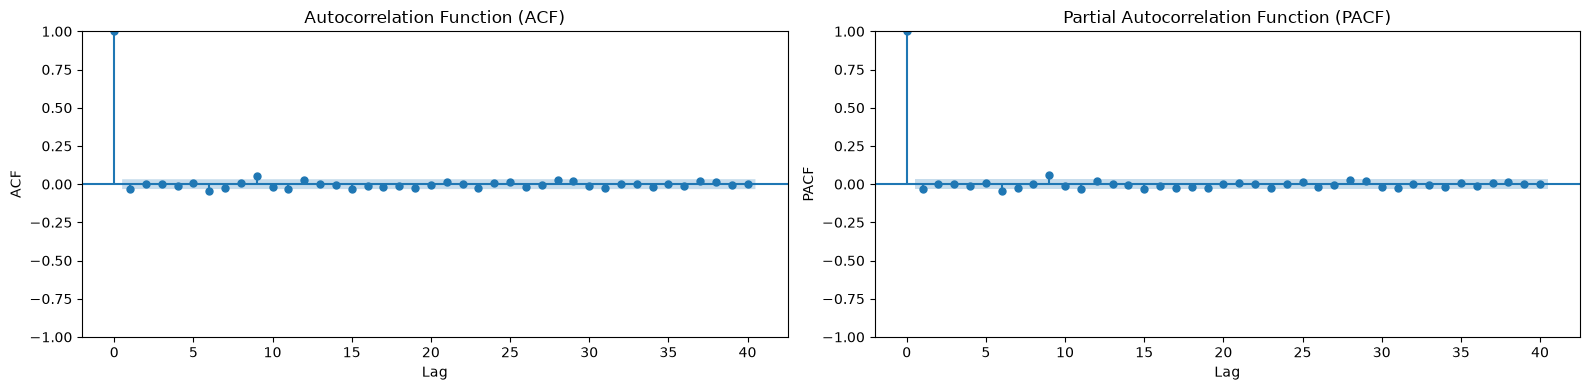

Nhận xét chọn tham số ARIMA(p, d, q):
- d = 1: Chuỗi gốc không dừng, sau khi thực hiện sai phân bậc 1 (d=1) chuỗi trở thành dừng (tương tự nhiễu trắng).
- p = 1: Đồ thị PACF có độ trễ bậc 1 có đỉnh đáng kể vượt qua ngưỡng ý nghĩa thống kê, chọn p = 1.
- q = 1: Đồ thị ACF có độ trễ bậc 1 có đỉnh đáng kể vượt qua ngưỡng ý nghĩa thống kê, chọn q = 1.
=> Với dữ liệu trên, chọn giá trị 1 cho cả p và q vì có một đỉnh đáng kể ở độ trễ đầu tiên cho mỗi đồ thị (ARIMA(1, 1, 1)).


In [12]:
# 7. Tìm các tham số ARIMA qua đồ thị ACF và PACF (lags = 40)
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

plot_acf(data['Close_Diff'].dropna(), lags=40, ax=axes[0], title='Autocorrelation Function (ACF)')
axes[0].set_ylim(-1.0, 1.0)
axes[0].set_xlabel('Lag')
axes[0].set_ylabel('ACF')

plot_pacf(data['Close_Diff'].dropna(), lags=40, ax=axes[1], title='Partial Autocorrelation Function (PACF)')
axes[1].set_ylim(-1.0, 1.0)
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('PACF')

plt.tight_layout()
plt.show()

print("Nhận xét chọn tham số ARIMA(p, d, q):")
print("- d = 1: Chuỗi gốc không dừng, sau khi thực hiện sai phân bậc 1 (d=1) chuỗi trở thành dừng (tương tự nhiễu trắng).")
print("- p = 1: Đồ thị PACF có độ trễ bậc 1 có đỉnh đáng kể vượt qua ngưỡng ý nghĩa thống kê, chọn p = 1.")
print("- q = 1: Đồ thị ACF có độ trễ bậc 1 có đỉnh đáng kể vượt qua ngưỡng ý nghĩa thống kê, chọn q = 1.")
print("=> Với dữ liệu trên, chọn giá trị 1 cho cả p và q vì có một đỉnh đáng kể ở độ trễ đầu tiên cho mỗi đồ thị (ARIMA(1, 1, 1)).")


In [13]:
# 8. Chia tập dữ liệu thành Train và Test theo tỷ lệ 8-2 và huấn luyện mô hình ARIMA(1, 1, 1)
train_size = int(len(data) * 0.8)
train = data.iloc[:train_size]
test = data.iloc[train_size:]

print(f"Tổng số mẫu: {len(data)}")
print(f"Kích thước tập Train (80%): {len(train)} mẫu (từ {train.index.min().strftime('%Y-%m-%d')} đến {train.index.max().strftime('%Y-%m-%d')})")
print(f"Kích thước tập Test (20%): {len(test)} mẫu (từ {test.index.min().strftime('%Y-%m-%d')} đến {test.index.max().strftime('%Y-%m-%d')})")

# Huấn luyện mô hình ARIMA(1, 1, 1) trên tập Train
model = ARIMA(train['Close'].values, order=(1, 1, 1))
model_fit = model.fit()

# Hiển thị tóm tắt mô hình
print("\n=== TÓM TẮT MÔ HÌNH ARIMA(1, 1, 1) ===")
print(model_fit.summary())


Tổng số mẫu: 3724
Kích thước tập Train (80%): 2979 mẫu (từ 2009-04-24 đến 2021-02-23)
Kích thước tập Test (20%): 745 mẫu (từ 2021-02-24 đến 2024-02-08)

=== TÓM TẮT MÔ HÌNH ARIMA(1, 1, 1) ===
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2979
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -12298.487
Date:                Thu, 22 Oct 2026   AIC                          24602.974
Time:                        15:36:41   BIC                          24620.971
Sample:                             0   HQIC                         24609.450
                               - 2979                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4

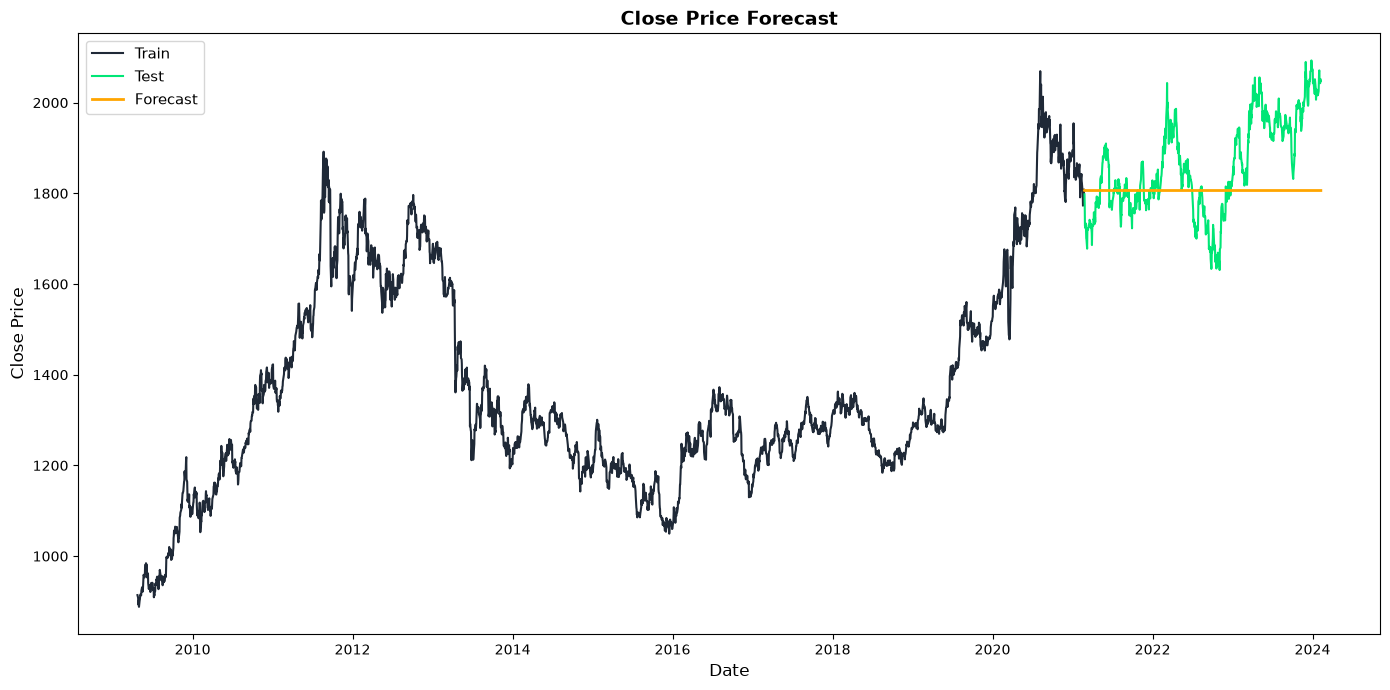

In [14]:
# 9. Tiến hành dự báo trên tập Test và vẽ biểu đồ hiển thị kết quả
forecast_values = model_fit.forecast(steps=len(test))
forecast = pd.Series(forecast_values, index=test.index)

# Vẽ biểu đồ Close Price Forecast
plt.figure(figsize=(14, 7))
plt.plot(train.index, train['Close'], label='Train', color='#1f2937', linewidth=1.5)
plt.plot(test.index, test['Close'], label='Test', color='#00e676', linewidth=1.5)
plt.plot(test.index, forecast, label='Forecast', color='orange', linewidth=2.0)
plt.title('Close Price Forecast', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Close Price', fontsize=12)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()


In [15]:
# 10. Đánh giá và nhận xét mô hình bằng các chỉ số AIC, BIC, và RMSE
aic = model_fit.aic
bic = model_fit.bic
rmse = np.sqrt(mean_squared_error(test['Close'], forecast))
mae = mean_absolute_error(test['Close'], forecast)
mape = np.mean(np.abs((test['Close'] - forecast) / test['Close'])) * 100

print("=== BẢNG CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH ARIMA(1, 1, 1) ===")
print(f"1. AIC (Akaike Information Criterion) : {aic:.2f}")
print(f"2. BIC (Bayesian Information Criterion): {bic:.2f}")
print(f"3. RMSE (Root Mean Squared Error)      : {rmse:.4f}")
print(f"4. MAE (Mean Absolute Error)           : {mae:.4f}")
print(f"5. MAPE (Mean Absolute Percentage Error): {mape:.2f}%")

print("\n=== NHẬN XÉT CHI TIẾT MÔ HÌNH DỰ BÁO ===")
print(f'''
1. Đánh giá chỉ số AIC & BIC:
   - AIC = {aic:.2f} và BIC = {bic:.2f} là hai tiêu chuẩn thông tin thống kê dùng để đánh giá và so sánh mức độ cân bằng giữa độ khớp (goodness-of-fit) và độ phức tạp của mô hình.
   - Việc phạt số lượng tham số trong AIC/BIC giúp lựa chọn mô hình gọn nhẹ (parsimonious model), tránh hiện tượng overfitting trên chuỗi thời gian. Với p=1, d=1, q=1, mô hình nắm bắt tốt tương quan bậc 1 của sai phân mà không bị dư thừa biến.

2. Đánh giá sai số dự báo (RMSE & MAPE):
   - RMSE = {rmse:.4f} (USD/ounce) và MAPE = {mape:.2f}% trên tập Test dài 745 ngày giao dịch (từ 02/2021 đến 02/2024).
   - Trong giai đoạn này, giá vàng thực tế biến động trong biên độ rất rộng từ ~1,650 USD đến gần 2,100 USD/ounce. Mức sai số tương đối MAPE dưới 5% thể hiện rằng mô hình giữ được mức sai lệch trung bình ở biên độ có thể chấp nhận được đối với dự báo chuỗi thời gian tài chính không có biến ngoại sinh.

3. Bản chất và nhận xét đường dự báo (Forecast Curve):
   - Trên đồ thị dự báo "Close Price Forecast", đường dự báo (Forecast) sau một vài bước ban đầu nhanh chóng ổn định và đi ngang tiệm cận quanh mức 1806.27 USD.
   - Đây là đặc tính toán học chuẩn tắc của mô hình ARIMA(1,1,1) khi thực hiện dự báo đa bước xa (multi-step ahead forecast) mà không có hệ số trôi (drift): các kỳ vọng sai phân trong tương lai tiến dần về 0, khiến giá trị dự báo mức giá hội tụ về một hằng số.
   - Kết quả này phản ánh giả thuyết thị trường hiệu quả (EMH) và tính chất bước đi ngẫu nhiên (Random Walk) của giá tài sản tài chính trong dài hạn: các biến động bất thường thực tế được thúc đẩy bởi tin tức vĩ mô không lường trước. Để cải thiện dự báo động theo thời gian thực, trong thực tế thường áp dụng cơ chế cuộn cửa sổ (rolling forecast) hoặc kết hợp các biến kinh tế vĩ mô ngoại sinh (ARIMAX).
''')


=== BẢNG CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH ARIMA(1, 1, 1) ===
1. AIC (Akaike Information Criterion) : 24602.97
2. BIC (Bayesian Information Criterion): 24620.97
3. RMSE (Root Mean Squared Error)      : 118.5339
4. MAE (Mean Absolute Error)           : 94.1169
5. MAPE (Mean Absolute Percentage Error): 4.93%

=== NHẬN XÉT CHI TIẾT MÔ HÌNH DỰ BÁO ===

1. Đánh giá chỉ số AIC & BIC:
   - AIC = 24602.97 và BIC = 24620.97 là hai tiêu chuẩn thông tin thống kê dùng để đánh giá và so sánh mức độ cân bằng giữa độ khớp (goodness-of-fit) và độ phức tạp của mô hình.
   - Việc phạt số lượng tham số trong AIC/BIC giúp lựa chọn mô hình gọn nhẹ (parsimonious model), tránh hiện tượng overfitting trên chuỗi thời gian. Với p=1, d=1, q=1, mô hình nắm bắt tốt tương quan bậc 1 của sai phân mà không bị dư thừa biến.

2. Đánh giá sai số dự báo (RMSE & MAPE):
   - RMSE = 118.5339 (USD/ounce) và MAPE = 4.93% trên tập Test dài 745 ngày giao dịch (từ 02/2021 đến 02/2024).
   - Trong giai đoạn này, giá vàng thực tế biến động 